# ¿Cuándo deja de ser rentable 1 MW minando Bitcoin?
### Proyecto final de Machine Learning. Caso de estudio: Offtake / [mw-index](https://github.com/Hoblayerta/mw-index)

Un minero de Bitcoin gana según el **hashprice**: los dólares que paga la red por cada PH/s en un día. Cuando el hashprice cae, la flota vieja deja de ganar y el operador tiene que decidir si pasa sus MW a alojar IA.

**Qué vamos a hacer:**
1. **EDA:** ver los datos (una fila por día, 2016 a 2026) y cuántos días al año cada flota dio negativo.
2. **Clasificación (regresión logística):** con lo que la red muestra hoy, ¿la flota vieja sigue rentable dentro de 30 días?
3. **Regresión (lineal y SVR):** cuánto crece el hashrate de la red según el precio de Bitcoin y el ciclo del halving.
4. **Fórmula:** a qué precio de Bitcoin cada flota vuelve a empatar con alojar IA.

**Por qué desde 2016:** antes la red era tan chica que el hashprice valía miles de dólares por PH. Desde 2016 es el mercado que conocemos (ASIC, pools, halving cada 4 años).

**Por qué 7 centavos por kWh:** 1 MW consume 24,000 kWh al día. A 7 c son 1,680 USD diarios de luz. Luxor estima que el minero promedio paga 4.8 c, pero con esa tarifa casi ningún día sale no rentable y el modelo no tiene qué aprender.

In [1]:
#Librerias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.svm import SVR #Support Vector Regressor

In [2]:
#Importar el dataset: una fila por dia, del 1 ene 2016 al 28 sep 2026
data = pd.read_csv("mw_bitcoin_diario.csv", index_col=0)
data.info()

<class 'pandas.DataFrame'>
Index: 3921 entries, 2016-01-01 to 2026-09-28
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   anio                     3921 non-null   int64  
 1   mes                      3921 non-null   int64  
 2   dia_semana               3921 non-null   int64  
 3   ciclo_halving            3921 non-null   int64  
 4   dias_desde_halving       3921 non-null   int64  
 5   btc_usd                  3921 non-null   float64
 6   hashrate_eh_s            3921 non-null   float64
 7   dificultad_t             3921 non-null   float64
 8   fees_usd_dia             3921 non-null   float64
 9   fees_pct_ingreso         3921 non-null   float64
 10  ingreso_minero_usd_dia   3921 non-null   float64
 11  n_transacciones          3921 non-null   float64
 12  tam_bloque_mb            3921 non-null   float64
 13  costo_por_tx_usd         3921 non-null   float64
 14  hashprice_usd_ph_dia     

## 1. EDA: ver los datos antes de modelar

In [3]:
#Estadisticas basicas de cada columna
data.describe().round(2)

,anio,mes,dia_semana,ciclo_halving,dias_desde_halving,btc_usd,hashrate_eh_s,dificultad_t,fees_usd_dia,fees_pct_ingreso,...,costo_por_tx_usd,hashprice_usd_ph_dia,mw_vieja_neto_usd_dia,mw_media_neto_usd_dia,mw_nueva_neto_usd_dia,hashprice_30d_despues,mw_vieja_rentable_30d,mw_vieja_margen_30d_usd,mw_media_margen_30d_usd,mw_nueva_margen_30d_usd
count,3921.00,3921.00,3921.0,3921.00,3921.00,3921.00,3921.00,3921.00,3921.00,3921.00,...,3921.00,3921.00,3921.00,3921.00,3921.00,3921.00,3921.00,3921.00,3921.00,3921.00
mean,2020.88,6.41,4.0,2.77,674.91,33142.28,301.67,41.81,1140271.65,4.46,...,73.19,359.37,10501.94,18855.27,24939.80,344.24,0.86,307146.14,552320.64,730904.53
std,3.10,3.42,2.0,0.85,405.97,32831.14,338.25,46.84,2572409.15,5.64,...,52.36,502.83,17045.25,28733.42,37247.02,481.40,0.35,489857.35,825759.53,1070429.02
min,2016.00,1.00,1.0,1.00,0.00,363.75,0.69,0.10,8783.06,0.29,...,3.87,28.13,-726.39,-72.48,403.82,28.13,0.00,-18120.72,4013.64,20136.20
25%,2018.00,3.00,2.0,2.00,326.00,6637.41,40.93,5.65,199104.35,1.15,...,38.19,63.37,468.26,1941.36,3014.35,62.55,1.00,13824.09,57863.46,89941.53
50%,2021.00,6.00,4.0,3.00,654.00,20568.90,145.67,20.00,435144.32,2.01,...,59.88,150.89,3435.07,6942.54,9497.37,147.32,1.00,103155.41,208450.54,285147.00
75%,2024.00,9.00,6.0,3.00,1025.00,58011.47,521.70,72.35,914151.56,5.53,...,102.27,375.10,11035.27,19754.31,26105.22,366.53,1.00,316737.52,568488.96,751863.46
max,2026.00,12.00,7.0,4.00,1439.00,124776.68,1305.50,155.97,81050337.22,75.22,...,300.31,3793.33,126907.37,215081.57,279307.22,3793.33,1.00,3063940.77,5199488.73,6755011.31


In [4]:
#Dias en que cada flota dio negativo (gasto mas luz de lo que gano), por año
#Flota vieja = 29.5 J/TH (S19j Pro), media = 17.5 (S21), nueva = 13.5 (S21 XP), luz a 0.07 USD/kWh
vieja_negativa = data[data['mw_vieja_neto_usd_dia'] < 0]
media_negativa = data[data['mw_media_neto_usd_dia'] < 0]
nueva_negativa = data[data['mw_nueva_neto_usd_dia'] < 0]

print("Flota vieja, dias negativos en total:", vieja_negativa.shape[0], "de", data.shape[0])
print(" - en 2024:", vieja_negativa[vieja_negativa['anio'] == 2024].shape[0])
print(" - en 2025:", vieja_negativa[vieja_negativa['anio'] == 2025].shape[0])
print(" - en 2026:", vieja_negativa[vieja_negativa['anio'] == 2026].shape[0], "de", data[data['anio'] == 2026].shape[0])
print("Flota media, dias negativos en total:", media_negativa.shape[0])
print("Flota nueva, dias negativos en total:", nueva_negativa.shape[0])

Flota vieja, dias negativos en total: 522 de 3921
 - en 2024: 124
 - en 2025: 128
 - en 2026: 270 de 271
Flota media, dias negativos en total: 6
Flota nueva, dias negativos en total: 0


In [5]:
#Cuanto pesan las fees (comisiones) en lo que gana un minero
print(f"Fees como % del ingreso minero: promedio {data['fees_pct_ingreso'].mean():.1f}%, mediana {data['fees_pct_ingreso'].median():.1f}%, maximo {data['fees_pct_ingreso'].max():.1f}%")
fees_altas = data[data['fees_pct_ingreso'] > 50]
print("Dias con fees arriba del 50% del ingreso:", fees_altas.shape[0])
fees_altas[['btc_usd', 'fees_pct_ingreso', 'hashprice_usd_ph_dia']]

Fees como % del ingreso minero: promedio 4.5%, mediana 2.0%, maximo 75.2%
Dias con fees arriba del 50% del ingreso: 1


,btc_usd,fees_pct_ingreso,hashprice_usd_ph_dia
fecha,,,
2024-04-20,63823.55,75.2166,193.0169


In [6]:
#Correlacion de las variables con el hashrate (lo que vamos a predecir en la regresion)
corr_matrix = data.corr(method = "pearson", numeric_only = True)["hashrate_eh_s"].sort_values(ascending = False)
corr_matrix

hashrate_eh_s              1.000000
dificultad_t               0.991889
btc_usd                    0.902039
anio                       0.897864
ciclo_halving              0.864918
tam_bloque_mb              0.731873
n_transacciones            0.731468
ingreso_minero_usd_dia     0.658364
costo_por_tx_usd           0.266527
mes                        0.013939
fees_usd_dia               0.011678
dia_semana                 0.006231
dias_desde_halving        -0.062264
fees_pct_ingreso          -0.234832
hashprice_30d_despues     -0.488452
hashprice_usd_ph_dia      -0.489961
mw_nueva_neto_usd_dia     -0.489961
mw_media_neto_usd_dia     -0.489961
mw_vieja_neto_usd_dia     -0.489961
mw_media_margen_30d_usd   -0.499433
mw_nueva_margen_30d_usd   -0.499433
mw_vieja_margen_30d_usd   -0.499433
mw_vieja_rentable_30d     -0.700967
Name: hashrate_eh_s, dtype: float64

In [7]:
#Correlacion con el objetivo de la clasificacion (flota vieja rentable 30 dias despues)
#OJO: hashprice_30d_despues tambien es del futuro y no se usa como entrada
corr_rentable = data.corr(method = "pearson", numeric_only = True)["mw_vieja_rentable_30d"].sort_values(ascending = False)
corr_rentable

mw_vieja_rentable_30d      1.000000
mw_media_margen_30d_usd    0.260190
mw_nueva_margen_30d_usd    0.260190
mw_vieja_margen_30d_usd    0.260190
hashprice_30d_despues      0.255409
hashprice_usd_ph_dia       0.254634
mw_media_neto_usd_dia      0.254634
mw_nueva_neto_usd_dia      0.254634
mw_vieja_neto_usd_dia      0.254634
fees_pct_ingreso           0.217515
dias_desde_halving         0.123364
fees_usd_dia               0.095009
costo_por_tx_usd           0.007357
mes                        0.004706
dia_semana                -0.001832
ingreso_minero_usd_dia    -0.289047
tam_bloque_mb             -0.409933
btc_usd                   -0.550158
anio                      -0.572869
ciclo_halving             -0.576273
n_transacciones           -0.596003
hashrate_eh_s             -0.700967
dificultad_t              -0.711831
Name: mw_vieja_rentable_30d, dtype: float64

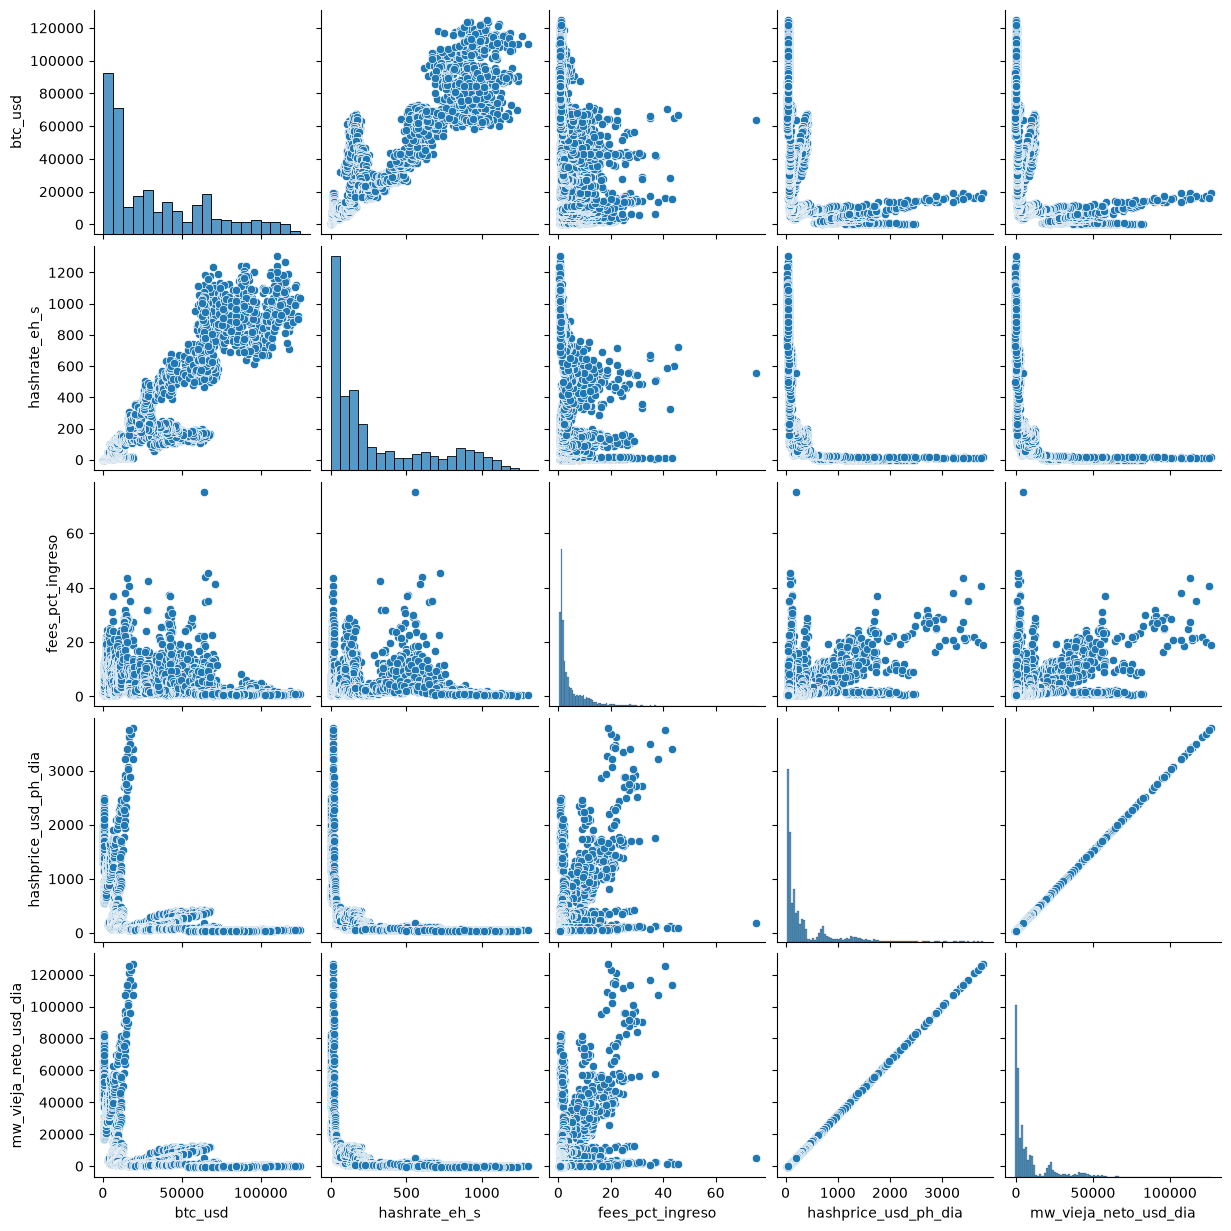

In [8]:
#Pairplot de las variables de interes
cols_pairplot = ['btc_usd', 'hashrate_eh_s', 'fees_pct_ingreso', 'hashprice_usd_ph_dia', 'mw_vieja_neto_usd_dia']
sns.pairplot(data=data[cols_pairplot])

### ¿Hay correlación entre el precio del cómputo de IA y el de Bitcoin?
Usamos la tabla mensual de mw-index, que ya tiene hashprice y precio de H100 por mes. Solo hay unos cuantos meses con los dos datos.

In [9]:
#Tabla mensual de mw-index (hashprice y precio por hora de una H100)
tabla = pd.read_csv("../out/tabla_mw.csv")
ia_vs_btc = tabla[['hashprice_usd_ph_dia', 'h100_usd_hora']]
print("Meses con precio de H100:", ia_vs_btc[ia_vs_btc['h100_usd_hora'] > 0].shape[0])
ia_vs_btc.corr(method = "pearson")

Meses con precio de H100: 15


,hashprice_usd_ph_dia,h100_usd_hora
hashprice_usd_ph_dia,1.000000,-0.443491
h100_usd_hora,-0.443491,1.000000


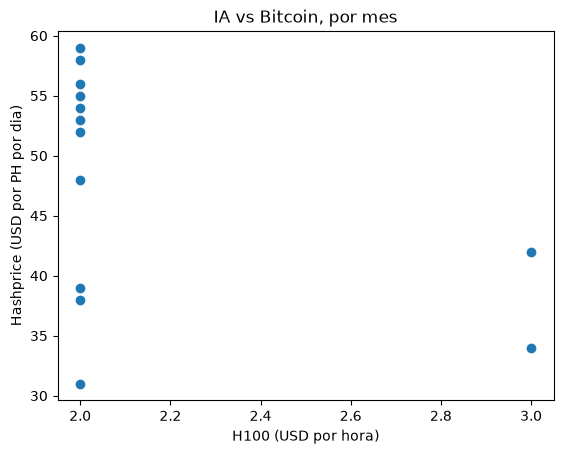

In [10]:
#Grafica de dispersion H100 vs hashprice
plt.scatter(tabla['h100_usd_hora'], tabla['hashprice_usd_ph_dia'])
plt.xlabel("H100 (USD por hora)")
plt.ylabel("Hashprice (USD por PH por dia)")
plt.title("IA vs Bitcoin, por mes")
plt.show()

**Lectura:** son muy pocos meses con los dos datos. No alcanza para un modelo. Los contratos de hosting se firman a años y el precio del token no entra en el hashprice. Se dice y se sigue.

## 2. Clasificación: ¿la flota vieja sigue rentable dentro de 30 días?
Objetivo: `mw_vieja_rentable_30d` (1 = sí, 0 = no). Entradas: lo que la red muestra **hoy**. Nunca una columna `*_30d`.

In [11]:
#Definimos target (salida) y features (entrada)
y_clas = data['mw_vieja_rentable_30d']

features_clas = ['btc_usd', 'hashrate_eh_s', 'fees_pct_ingreso', 'dificultad_t', 'dias_desde_halving']
x_clas = data[features_clas]

print("Matriz X predictoras: ", x_clas.shape)
print("Vector Y target: ", y_clas.shape)
print("Dias rentables:", data[data['mw_vieja_rentable_30d'] == 1].shape[0], " Dias no rentables:", data[data['mw_vieja_rentable_30d'] == 0].shape[0])

Matriz X predictoras:  (3921, 5)
Vector Y target:  (3921,)
Dias rentables: 3369  Dias no rentables: 552


In [12]:
#Dividimos en train y test (aleatorio, como en clase)
x_train_c, x_test_c, y_train_c, y_test_c = train_test_split(x_clas, y_clas, test_size=0.15, random_state=100)
print(f"Dias para entrenar: {x_train_c.shape[0]} y para probar: {x_test_c.shape[0]}")

Dias para entrenar: 3332 y para probar: 589


In [13]:
#Creamos el escalador y escalamos
escalador = StandardScaler()
x_train_c_scaled = escalador.fit_transform(x_train_c)
x_test_c_scaled = escalador.transform(x_test_c)

In [14]:
#Instanciamos el modelo
modelo_log = LogisticRegression(max_iter=500, random_state=100)

#Entrenamos el modelo
modelo_log.fit(x_train_c_scaled, y_train_c)

#Generamos predicciones
y_pred_test_c = modelo_log.predict(x_test_c_scaled)
y_pred_train_c = modelo_log.predict(x_train_c_scaled)

print("Primeras 10 predicciones del modelo:", y_pred_test_c[:10])
print("Resultados reales de esos 10 dias:  ", y_test_c[:10].tolist())

Primeras 10 predicciones del modelo: [1 0 1 1 1 1 0 1 1 1]
Resultados reales de esos 10 dias:   [1, 1, 1, 1, 1, 1, 0, 1, 1, 1]


In [15]:
#Metricas. pos_label=0 porque lo que nos importa detectar es el dia NO rentable (como en clase era Maligno = 0)
exactitud = accuracy_score(y_test_c, y_pred_test_c)
precision = precision_score(y_test_c, y_pred_test_c, pos_label=0)
exhaustividad = recall_score(y_test_c, y_pred_test_c, pos_label=0)
f1 = f1_score(y_test_c, y_pred_test_c, pos_label=0)

print("---Split aleatorio---")
print(f"El valor de la exactitud es : {exactitud * 100:.2f}%")
print(f"El valor de la precision es : {precision * 100:.2f}%")
print(f"El valor de la exhaustividad es : {exhaustividad * 100:.2f}%")
print(f"El valor de la puntuacion F1 es : {f1 * 100:.2f}%")

---Split aleatorio---
El valor de la exactitud es : 96.77%
El valor de la precision es : 87.36%
El valor de la exhaustividad es : 90.48%
El valor de la puntuacion F1 es : 88.89%


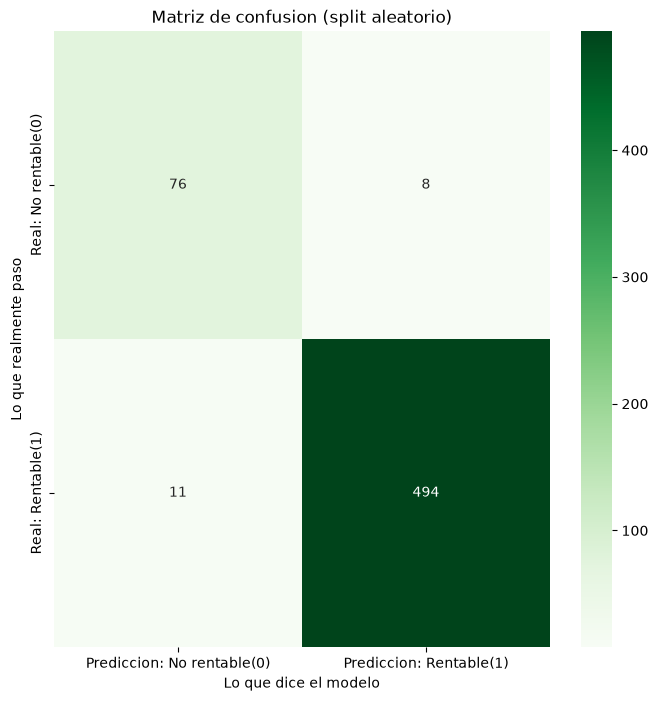

In [16]:
#Matriz de confusion
matriz = confusion_matrix(y_test_c, y_pred_test_c)

plt.figure(figsize=(8,8))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Prediccion: No rentable(0)", "Prediccion: Rentable(1)"],
            yticklabels=["Real: No rentable(0)", "Real: Rentable(1)"])
plt.title("Matriz de confusion (split aleatorio)")
plt.ylabel("Lo que realmente paso")
plt.xlabel("Lo que dice el modelo")
plt.show()

### El mismo modelo, pero entrenando con el pasado y probando con el futuro
Con el split aleatorio, dos días seguidos (que se parecen casi igual) pueden caer uno en train y otro en test, y eso infla los números. Lo honesto es entrenar con el pasado y probar con 2025 y 2026, que el modelo nunca vio.

Ojo: el objetivo mira 30 días adelante. Si entrenamos hasta el 31 de diciembre de 2024, la etiqueta del 2 de diciembre ya usa lo que pasó en enero de 2025. Por eso entrenamos solo **hasta noviembre de 2024**.

In [17]:
#Partimos por fecha: entrenamos hasta noviembre 2024 (para que ninguna etiqueta use dias de 2025) y probamos con 2025 y 2026
antes_de_2024 = data[data['anio'] < 2024]
hasta_nov_2024 = data[data['anio'] == 2024]
hasta_nov_2024 = hasta_nov_2024[hasta_nov_2024['mes'] <= 11]
entrena = pd.concat([antes_de_2024, hasta_nov_2024])
prueba = data[data['anio'] >= 2025]
print(f"Dias para entrenar: {entrena.shape[0]} (2016 a nov 2024) y para probar: {prueba.shape[0]} (2025 y 2026)")

x_train_f = entrena[features_clas]
y_train_f = entrena['mw_vieja_rentable_30d']
x_test_f = prueba[features_clas]
y_test_f = prueba['mw_vieja_rentable_30d']

#Escalamos
escalador_f = StandardScaler()
x_train_f_scaled = escalador_f.fit_transform(x_train_f)
x_test_f_scaled = escalador_f.transform(x_test_f)

#Entrenamos y predecimos
modelo_log_f = LogisticRegression(max_iter=500, random_state=100)
modelo_log_f.fit(x_train_f_scaled, y_train_f)
y_pred_test_f = modelo_log_f.predict(x_test_f_scaled)

print("\n---Split por fecha---")
print(f"El valor de la exactitud es : {accuracy_score(y_test_f, y_pred_test_f) * 100:.2f}%")
print(f"El valor de la precision es : {precision_score(y_test_f, y_pred_test_f, pos_label=0) * 100:.2f}%")
print(f"El valor de la exhaustividad es : {recall_score(y_test_f, y_pred_test_f, pos_label=0) * 100:.2f}%")
print(f"El valor de la puntuacion F1 es : {f1_score(y_test_f, y_pred_test_f, pos_label=0) * 100:.2f}%")

Dias para entrenar: 3257 (2016 a nov 2024) y para probar: 633 (2025 y 2026)

---Split por fecha---
El valor de la exactitud es : 67.77%
El valor de la precision es : 67.72%
El valor de la exhaustividad es : 100.00%
El valor de la puntuacion F1 es : 80.75%


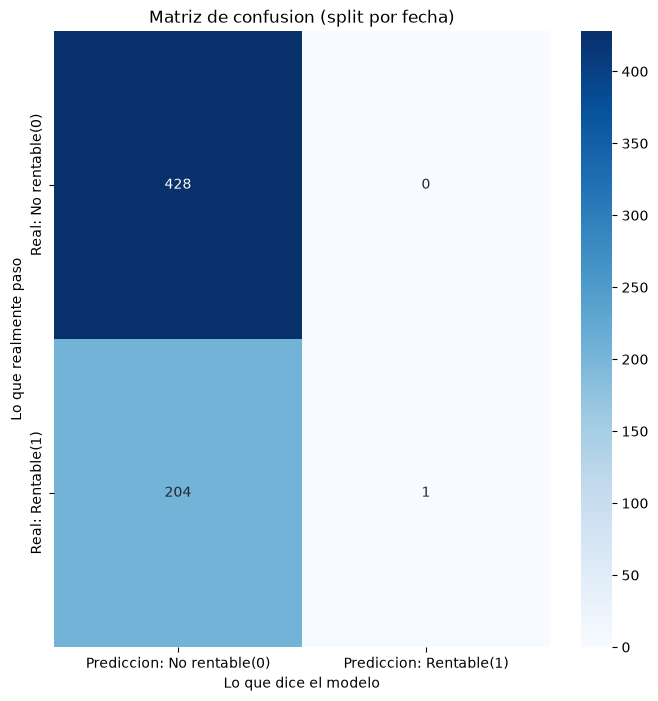

In [18]:
#Matriz de confusion del split por año
matriz_f = confusion_matrix(y_test_f, y_pred_test_f)

plt.figure(figsize=(8,8))
sns.heatmap(matriz_f, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prediccion: No rentable(0)", "Prediccion: Rentable(1)"],
            yticklabels=["Real: No rentable(0)", "Real: Rentable(1)"])
plt.title("Matriz de confusion (split por fecha)")
plt.ylabel("Lo que realmente paso")
plt.xlabel("Lo que dice el modelo")
plt.show()

### Comparamos contra lo más simple: suponer que en 30 días sigue como hoy
Un modelo solo sirve si le gana a la regla más tonta. Aquí la regla tonta es: si hoy la flota vieja gana, en 30 días también; si hoy pierde, en 30 días también.

In [19]:
#Baseline: en 30 dias sigue como hoy (1 si hoy el ingreso neto es positivo, 0 si no)
sigue_como_hoy = prueba['mw_vieja_neto_usd_dia'] > 0
sigue_como_hoy = sigue_como_hoy.map({True: 1, False: 0})

print("---Baseline: en 30 dias sigue como hoy---")
print(f"El valor de la exactitud es : {accuracy_score(y_test_f, sigue_como_hoy) * 100:.2f}%")
print(f"El valor de la precision es : {precision_score(y_test_f, sigue_como_hoy, pos_label=0) * 100:.2f}%")
print(f"El valor de la exhaustividad es : {recall_score(y_test_f, sigue_como_hoy, pos_label=0) * 100:.2f}%")
print(f"El valor de la puntuacion F1 es : {f1_score(y_test_f, sigue_como_hoy, pos_label=0) * 100:.2f}%")

#Cuantas veces cada uno dijo "no rentable" y cuantas eran falsas alarmas (dias que si fueron rentables)
print("\nDias de prueba:", prueba.shape[0], "| dias que si fueron rentables:", prueba[prueba['mw_vieja_rentable_30d'] == 1].shape[0])
print("Regresion logistica dijo 'no rentable':", (y_pred_test_f == 0).sum(), "veces")
print("Baseline dijo 'no rentable':", (sigue_como_hoy == 0).sum(), "veces")

---Baseline: en 30 dias sigue como hoy---
El valor de la exactitud es : 85.15%
El valor de la precision es : 91.96%
El valor de la exhaustividad es : 85.51%
El valor de la puntuacion F1 es : 88.62%

Dias de prueba: 633 | dias que si fueron rentables: 205
Regresion logistica dijo 'no rentable': 632 veces
Baseline dijo 'no rentable': 398 veces


**Lectura:** la regresión logística detecta todos los días malos, pero porque dice "malo" casi siempre. El baseline acierta más y se equivoca menos. Un modelo puede tener recall del 100% y aun así servir poco para decidir cuándo actuar.

### Lo que de verdad le importa al operador: ¿cuánto gana o pierde si sigue encendido 30 días?
`mw_vieja_margen_30d_usd` es la suma del ingreso neto de los próximos 30 días (hoy + 29). Tomamos todas las ventanas de 2026.

In [20]:
#Ventanas de 30 dias en 2026, por flota (luz a 7 c)
ventanas_2026 = data[data['anio'] == 2026]
print("Ventanas de 30 dias en 2026:", ventanas_2026.shape[0])

vieja_pierde = ventanas_2026[ventanas_2026['mw_vieja_margen_30d_usd'] < 0]
media_pierde = ventanas_2026[ventanas_2026['mw_media_margen_30d_usd'] < 0]
nueva_pierde = ventanas_2026[ventanas_2026['mw_nueva_margen_30d_usd'] < 0]

print(f"Flota vieja: pierde en {vieja_pierde.shape[0]} ventanas, margen mediano {ventanas_2026['mw_vieja_margen_30d_usd'].median():,.0f} USD, peor {ventanas_2026['mw_vieja_margen_30d_usd'].min():,.0f} USD")
print(f"Flota media: pierde en {media_pierde.shape[0]} ventanas, margen mediano {ventanas_2026['mw_media_margen_30d_usd'].median():,.0f} USD, peor {ventanas_2026['mw_media_margen_30d_usd'].min():,.0f} USD")
print(f"Flota nueva: pierde en {nueva_pierde.shape[0]} ventanas, margen mediano {ventanas_2026['mw_nueva_margen_30d_usd'].median():,.0f} USD, peor {ventanas_2026['mw_nueva_margen_30d_usd'].min():,.0f} USD")

#Tarifa de luz a la que la flota vieja hubiera quedado en equilibrio en 2026
hashprice_2026 = ventanas_2026['hashprice_usd_ph_dia'].mean()
ph_vieja = 1_000_000 / 29.5 / 1000
tarifa_equilibrio = hashprice_2026 * ph_vieja / 24000
print(f"\nHashprice promedio 2026: {hashprice_2026:.1f} USD/PH/dia")
print(f"Tarifa de equilibrio de la flota vieja: {tarifa_equilibrio * 100:.2f} centavos por kWh")

Ventanas de 30 dias en 2026: 271
Flota vieja: pierde en 271 ventanas, margen mediano -14,493 USD, peor -18,121 USD
Flota media: pierde en 0 ventanas, margen mediano 10,129 USD, peor 4,014 USD
Flota nueva: pierde en 0 ventanas, margen mediano 28,064 USD, peor 20,136 USD

Hashprice promedio 2026: 36.6 USD/PH/dia
Tarifa de equilibrio de la flota vieja: 5.17 centavos por kWh


**Lectura:** la flota vieja a 7 c pierde en todas las ventanas de 30 días de 2026 (unos 15 mil USD por MW al mes; para un sitio de 10 MW, 150 mil). La media y la nueva nunca pierden. Y el número para hablar con un operador: la vieja solo sobrevive con luz debajo de 5.2 c/kWh. Conocer su tarifa cambia la conclusión antes de hablar de IA.

## 3. Regresión: ¿cuánto crece el hashrate cuando sube el precio de Bitcoin?
Objetivo: `hashrate_eh_s`. Entradas: precio de Bitcoin y días desde el último halving (el ciclo).

In [21]:
#Vamos a definir el target (salida) y las features (entrada)
#Target: hashrate de la red
y = data['hashrate_eh_s']

#Input features: las 2 variables con mayor correlacion que no sean la misma cosa
#(dificultad se descarta porque se calcula del hashrate, seria predecir algo con si mismo)
features_predictors = ['btc_usd', 'dias_desde_halving']
x = data[features_predictors]

#Asegurarnos que las entradas y salidas son del mismo tamaño
print("Matriz X predictoras: ", x.shape)
print("Vector Y target: ", y.shape)
if x.shape[0] == y.shape[0]:
    print("Las entradas y salidas son del mismo tamaño, continua")
else:
    print("Las entradas y salidas no son del mismo tamaño, revisa tus datos")

Matriz X predictoras:  (3921, 2)
Vector Y target:  (3921,)
Las entradas y salidas son del mismo tamaño, continua


In [22]:
#Particionamos el conjunto de datos
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=100)
print("Muestras de entrenamiento ", y_train.shape[0])
print("Muestras de prueba", y_test.shape[0])

#Estandarizamos
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

Muestras de entrenamiento  3332
Muestras de prueba 589


In [23]:
#Generamos la funcion para las metricas
def print_metrics(y_real, y_pred, dataset_name):
    r2 = r2_score(y_real, y_pred)
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)

    print(f"---Metricas de evaluacion ({dataset_name})---")
    print(f"R2: {r2:.4f}")
    print(f"R2 en porcentaje: {r2 * 100:.2f}%")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")

### Regresión lineal múltiple

In [24]:
#Instanciamos y entrenamos el modelo de regresion lineal multiple
modelo_lineal = LinearRegression()
modelo_lineal.fit(x_train_scaled, y_train)

#Mostramos los coeficientes del modelo
print("Intercepto (w0)", round(modelo_lineal.intercept_, 2))
print("\n Coeficientes (wi) por variable ")
for col, coef in zip(features_predictors, modelo_lineal.coef_):
    print(f" - {col}: {round(coef, 2)}")
print("Mi ecuacion lineal multivariable es : w0 + w1x1 + w2x2")

Intercepto (w0) 300.84

 Coeficientes (wi) por variable 
 - btc_usd: 312.59
 - dias_desde_halving: 44.81
Mi ecuacion lineal multivariable es : w0 + w1x1 + w2x2


In [25]:
#Generamos predicciones y evaluamos
y_pred_train_lineal = modelo_lineal.predict(x_train_scaled)
y_pred_test_lineal = modelo_lineal.predict(x_test_scaled)

print_metrics(y_train, y_pred_train_lineal, "ENTRENAMIENTO")
print_metrics(y_test, y_pred_test_lineal, "PRUEBA")

---Metricas de evaluacion (ENTRENAMIENTO)---
R2: 0.8285
R2 en porcentaje: 82.85%
MAE: 99.1430
MSE: 19401.7897
RMSE: 139.2903
---Metricas de evaluacion (PRUEBA)---
R2: 0.8380
R2 en porcentaje: 83.80%
MAE: 100.7848
MSE: 19647.8926
RMSE: 140.1709


### Support Vector Regressor (SVR)

In [26]:
#Instanciamos el modelo
#epsilon=1 porque el hashrate va de 58 a 1,300 EH/s (en clase era 10 porque el area era de cientos)
SVR_model = SVR(kernel="rbf", C=100, gamma="scale", epsilon=1)

#Entrenamos el modelo
SVR_model.fit(x_train_scaled, y_train)

#Generamos predicciones
y_pred_train_svr = SVR_model.predict(x_train_scaled)
y_pred_test_svr = SVR_model.predict(x_test_scaled)

print_metrics(y_train, y_pred_train_svr, "ENTRENAMIENTO")
print_metrics(y_test, y_pred_test_svr, "PRUEBA")

---Metricas de evaluacion (ENTRENAMIENTO)---
R2: 0.9513
R2 en porcentaje: 95.13%
MAE: 42.7200
MSE: 5507.5500
RMSE: 74.2129
---Metricas de evaluacion (PRUEBA)---
R2: 0.9500
R2 en porcentaje: 95.00%
MAE: 44.2323
MSE: 6059.5883
RMSE: 77.8434


### Comparamos los modelos: ¿cuál tiene el R² más alto en prueba?

In [27]:
#Comparamos el R2 de prueba de los 3 modelos en porcentaje (split aleatorio)
r2_lineal = r2_score(y_test, y_pred_test_lineal)
r2_svr = r2_score(y_test, y_pred_test_svr)

print("---Split aleatorio---")
print(f"Regresion lineal multiple: {r2_lineal * 100:.2f}%")
print(f"Support Vector Regressor (SVR): {r2_svr * 100:.2f}%")

---Split aleatorio---
Regresion lineal multiple: 83.80%
Support Vector Regressor (SVR): 95.00%


In [28]:
#Los mismos 2 modelos pero entrenando hasta nov 2024 y probando con 2025 y 2026
x_train_a = entrena[features_predictors]
y_train_a = entrena['hashrate_eh_s']
x_test_a = prueba[features_predictors]
y_test_a = prueba['hashrate_eh_s']

scaler_a = StandardScaler()
x_train_a_scaled = scaler_a.fit_transform(x_train_a)
x_test_a_scaled = scaler_a.transform(x_test_a)

modelo_lineal_a = LinearRegression()
modelo_lineal_a.fit(x_train_a_scaled, y_train_a)
SVR_model_a = SVR(kernel="rbf", C=100, gamma="scale", epsilon=1)
SVR_model_a.fit(x_train_a_scaled, y_train_a)

print("---Split por fecha (prueba = 2025 y 2026)---")
print(f"Regresion lineal multiple: {r2_score(y_test_a, modelo_lineal_a.predict(x_test_a_scaled)) * 100:.2f}%")
print(f"Support Vector Regressor (SVR): {r2_score(y_test_a, SVR_model_a.predict(x_test_a_scaled)) * 100:.2f}%")
print(f"\nHashrate real promedio en 2025 y 2026: {y_test_a.mean():.0f} EH/s. El modelo lineal predice en promedio {modelo_lineal_a.predict(x_test_a_scaled).mean():.0f} EH/s")
print("R2 = 0% es predecir siempre el promedio, negativo es peor que el promedio")

---Split por fecha (prueba = 2025 y 2026)---
Regresion lineal multiple: -603.28%
Support Vector Regressor (SVR): -2322.07%

Hashrate real promedio en 2025 y 2026: 939 EH/s. El modelo lineal predice en promedio 679 EH/s
R2 = 0% es predecir siempre el promedio, negativo es peor que el promedio


### Gráfica 3D: precio de Bitcoin, días desde el halving y hashrate

In [29]:
#Crear el elemento interactivo en 3D
import plotly.express as px

# Agregamos si la flota vieja fue rentable 30 dias despues como texto (0 = No rentable, 1 = Rentable)
data['rentable'] = data['mw_vieja_rentable_30d'].map({0: 'No rentable', 1: 'Rentable'})

# Crear un grafico de dispersion 3D interactivo
fig = px.scatter_3d(
    data_frame=data,
    x='btc_usd',
    y='dias_desde_halving',
    z='hashrate_eh_s',
    color='rentable',
    color_discrete_map={'No rentable': '#f43f5e', 'Rentable': '#34d399'},
    opacity=0.7,
    title='Explorador 3D: precio de Bitcoin, ciclo del halving y hashrate',
    labels={
        'btc_usd': 'Precio de Bitcoin (USD)',
        'dias_desde_halving': 'Días desde el halving',
        'hashrate_eh_s': 'Hashrate (EH/s)'
    }
)

# Aplicar el tema oscuro de Plotly
fig.update_layout(
    template='plotly_dark',
    margin=dict(l=0, r=0, b=0, t=50),
    paper_bgcolor='#0f172a',
    plot_bgcolor='#0f172a'
)

# Mostrar el grafico interactivo
fig.show()

## 4. Regresión: ¿cuánto va a ganar o perder 1 MW en los próximos 30 días?
Objetivo: `mw_vieja_margen_30d_usd` (USD netos acumulados de los próximos 30 días, flota vieja). Entradas: lo que la red muestra hoy, incluido el margen de hoy. Entrenamos hasta nov 2024 y probamos con 2025 y 2026.

Baseline: "lo de hoy por 30" (el margen de hoy multiplicado por 30 días). Si un modelo no le gana a eso, no sirve para pronosticar.

In [30]:
#Target: margen acumulado de los proximos 30 dias (flota vieja)
#Input features: lo que la red muestra hoy + el margen de hoy
features_margen = ['btc_usd', 'hashrate_eh_s', 'fees_pct_ingreso', 'dificultad_t', 'dias_desde_halving', 'mw_vieja_neto_usd_dia']

x_train_m = entrena[features_margen]
y_train_m = entrena['mw_vieja_margen_30d_usd']
x_test_m = prueba[features_margen]
y_test_m = prueba['mw_vieja_margen_30d_usd']
print(f"Dias para entrenar: {x_train_m.shape[0]} y para probar: {x_test_m.shape[0]}")
print(f"Margen real a 30 dias en prueba: mediana {y_test_m.median():,.0f} USD, minimo {y_test_m.min():,.0f}, maximo {y_test_m.max():,.0f}")

#Escalamos
scaler_m = StandardScaler()
x_train_m_scaled = scaler_m.fit_transform(x_train_m)
x_test_m_scaled = scaler_m.transform(x_test_m)

Dias para entrenar: 3257 y para probar: 633
Margen real a 30 dias en prueba: mediana -6,416 USD, minimo -18,121, maximo 11,064


In [31]:
#Baseline: lo de hoy por 30
baseline_m = prueba['mw_vieja_neto_usd_dia'] * 30
print_metrics(y_test_m, baseline_m, "BASELINE: hoy x 30")

---Metricas de evaluacion (BASELINE: hoy x 30)---
R2: 0.8586
R2 en porcentaje: 85.86%
MAE: 2756.7189
MSE: 11932654.9836
RMSE: 3454.3675


In [32]:
#Regresion lineal multiple
modelo_lineal_m = LinearRegression()
modelo_lineal_m.fit(x_train_m_scaled, y_train_m)
y_pred_lineal_m = modelo_lineal_m.predict(x_test_m_scaled)
print_metrics(y_test_m, y_pred_lineal_m, "REGRESION LINEAL")

#SVR (epsilon=100 porque el margen esta en miles de USD)
SVR_model_m = SVR(kernel="rbf", C=100, gamma="scale", epsilon=100)
SVR_model_m.fit(x_train_m_scaled, y_train_m)
y_pred_svr_m = SVR_model_m.predict(x_test_m_scaled)
print_metrics(y_test_m, y_pred_svr_m, "SVR")

---Metricas de evaluacion (REGRESION LINEAL)---
R2: -14.8304
R2 en porcentaje: -1483.04%
MAE: 33308.2651
MSE: 1336178106.6129
RMSE: 36553.7701


---Metricas de evaluacion (SVR)---
R2: -275.4738
R2 en porcentaje: -27547.38%
MAE: 152422.7225
MSE: 23336005580.3361
RMSE: 152761.2699


In [33]:
#Comparamos el error en USD por MW al mes y cuantas veces acierta si gana o pierde
print(f"Baseline hoy x 30: MAE {mean_absolute_error(y_test_m, baseline_m):,.0f} USD por MW al mes")
print(f"Regresion lineal: MAE {mean_absolute_error(y_test_m, y_pred_lineal_m):,.0f} USD por MW al mes")
print(f"SVR: MAE {mean_absolute_error(y_test_m, y_pred_svr_m):,.0f} USD por MW al mes")

acierta_baseline = (baseline_m < 0) == (y_test_m < 0)
acierta_lineal = (y_pred_lineal_m < 0) == (y_test_m < 0)
print(f"\nAcierta si pierde o gana: baseline {acierta_baseline.mean() * 100:.1f}%, regresion lineal {acierta_lineal.mean() * 100:.1f}%")

Baseline hoy x 30: MAE 2,757 USD por MW al mes
Regresion lineal: MAE 33,308 USD por MW al mes
SVR: MAE 152,423 USD por MW al mes

Acierta si pierde o gana: baseline 92.9%, regresion lineal 64.3%


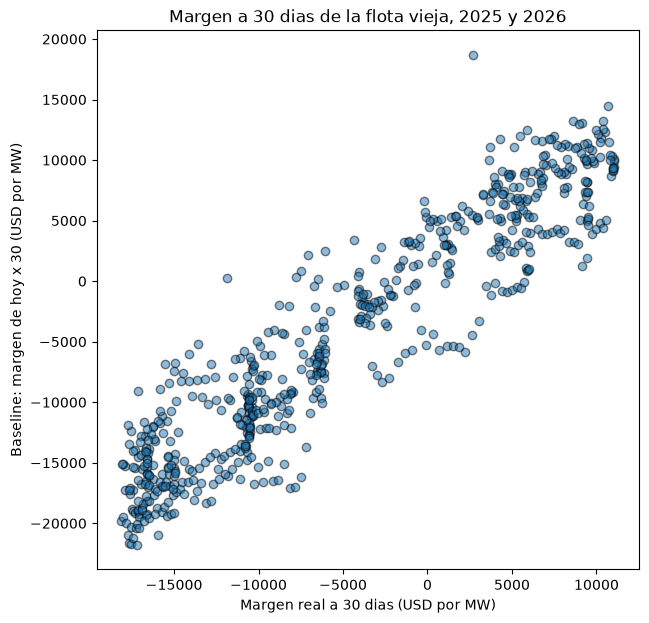

In [34]:
#Grafica de dispersion: margen real vs baseline (si fuera perfecto, los puntos caerian en una diagonal)
plt.figure(figsize=(7,7))
plt.scatter(y_test_m, baseline_m, alpha=0.5, edgecolors="black")
plt.xlabel("Margen real a 30 dias (USD por MW)")
plt.ylabel("Baseline: margen de hoy x 30 (USD por MW)")
plt.title("Margen a 30 dias de la flota vieja, 2025 y 2026")
plt.show()

**Lectura:** el baseline se equivoca por unos 2,800 USD por MW al mes y acierta el signo el 93% de las veces. Los dos modelos de clase se equivocan por más de 33 mil: 2025 y 2026 están fuera del rango que vieron. Para pronosticar el mes que viene, lo que el operador ve hoy en su recibo es mejor que cualquier modelo de clase.

## 5. Fórmula: ¿a qué precio de Bitcoin minar vuelve a ganarle a alojar IA?
Esto no es ML, es una resta. Alojar IA paga ~3,899 USD por MW al día (TeraWulf / Fluidstack). Minar paga hashprice × PH/s que caben en 1 MW, menos la luz. Con el hashrate y las fees de hoy, el hashprice sube igual que el precio de Bitcoin.

In [35]:
#Tomamos septiembre 2026 (el ultimo mes del dataset) como "hoy"
sep_2026 = data[data['anio'] == 2026]
sep_2026 = sep_2026[sep_2026['mes'] == 9]
hashprice_hoy = sep_2026['hashprice_usd_ph_dia'].mean()
btc_hoy = sep_2026['btc_usd'].mean()
print(f"Septiembre 2026: hashprice {hashprice_hoy:.1f} USD/PH/dia, Bitcoin {btc_hoy:,.0f} USD")

#PH/s que caben en 1 MW con cada flota: 1,000,000 W / (J/TH) / 1000
ph_vieja = 1_000_000 / 29.5 / 1000
ph_media = 1_000_000 / 17.5 / 1000
ph_nueva = 1_000_000 / 13.5 / 1000
print(f"PH/s por MW: vieja {ph_vieja:.1f}, media {ph_media:.1f}, nueva {ph_nueva:.1f}")

#Lo que tiene que pagar minar para empatar con hosting: hosting + luz (7 c)
hosting = 3899
luz = 24 * 1000 * 0.07
meta = hosting + luz
print(f"Minar tiene que dejar {meta:.0f} USD por MW al dia (hosting {hosting} + luz {luz:.0f})")

Septiembre 2026: hashprice 43.3 USD/PH/dia, Bitcoin 80,077 USD
PH/s por MW: vieja 33.9, media 57.1, nueva 74.1
Minar tiene que dejar 5579 USD por MW al dia (hosting 3899 + luz 1680)


In [36]:
#Hashprice necesario para cada flota = meta / PH por MW
#Precio de Bitcoin necesario = precio de hoy * (hashprice necesario / hashprice de hoy)
hp_vieja = meta / ph_vieja
hp_media = meta / ph_media
hp_nueva = meta / ph_nueva

print(f"Flota vieja: necesita hashprice {hp_vieja:.0f} -> Bitcoin en {btc_hoy * hp_vieja / hashprice_hoy:,.0f} USD")
print(f"Flota media: necesita hashprice {hp_media:.0f} -> Bitcoin en {btc_hoy * hp_media / hashprice_hoy:,.0f} USD")
print(f"Flota nueva: necesita hashprice {hp_nueva:.0f} -> Bitcoin en {btc_hoy * hp_nueva / hashprice_hoy:,.0f} USD")

#Y si la IA se abarata y el hosting paga la mitad
meta_mitad = hosting / 2 + luz
print(f"\nSi el hosting paga la mitad ({hosting / 2:.0f} USD):")
print(f"Flota vieja: Bitcoin en {btc_hoy * (meta_mitad / ph_vieja) / hashprice_hoy:,.0f} USD")
print(f"Flota media: Bitcoin en {btc_hoy * (meta_mitad / ph_media) / hashprice_hoy:,.0f} USD")
print(f"Flota nueva: Bitcoin en {btc_hoy * (meta_mitad / ph_nueva) / hashprice_hoy:,.0f} USD")

Flota vieja: necesita hashprice 165 -> Bitcoin en 304,515 USD
Flota media: necesita hashprice 98 -> Bitcoin en 180,644 USD
Flota nueva: necesita hashprice 75 -> Bitcoin en 139,354 USD

Si el hosting paga la mitad (1950 USD):
Flota vieja: Bitcoin en 198,107 USD
Flota media: Bitcoin en 117,521 USD
Flota nueva: Bitcoin en 90,659 USD


## Conclusiones

1. **Qué pasa con la clasificación:** con split aleatorio la regresión logística da 96.8% de exactitud y 90.5% de recall, pero es por días vecinos. Entrenando hasta nov 2024 y probando con 2025 y 2026 detecta el 100% de los días malos porque dice "malo" 632 de 633 días. El baseline "en 30 días sigue como hoy" acierta más (85.2% vs 67.8%) y se equivoca menos. **Un modelo puede tener recall del 100% y servir poco para decidir cuándo actuar.**
2. **Qué no predice:** el hashrate futuro. Con split aleatorio los 2 regresores dan R² de 84% (lineal) y 95% (SVR), pero por fecha el R² sale negativo en los 2: el hashrate de 2025 y 2026 está fuera de todo lo que los modelos vieron. Ningún modelo de clase extrapola.
3. **Qué dicen los datos sin modelo:** la flota vieja (29.5 J/TH) a 7 c/kWh pierde en las 271 ventanas de 30 días de 2026, unos 14.5 mil USD por MW al mes (para 10 MW, 145 mil). La media y la nueva nunca pierden en 30 días. La vieja solo queda en equilibrio con luz debajo de **5.17 c/kWh**. Las fees pesan 4.5% del ingreso minero en promedio; solo un día pasó del 50% (20 abr 2024, Runes).
4. **Predecir el margen a 30 días:** el baseline "lo de hoy por 30" se equivoca por ~2,800 USD por MW al mes y acierta el signo el 93% de las veces; los 2 regresores de clase se equivocan por más de 33 mil. Lo que el operador ve hoy en su recibo es mejor pronóstico que cualquier modelo de clase.
5. **Para Offtake:** la pregunta útil no es "¿será rentable el día 30?" sino "¿cuánto pierde por MW si sigue encendido un mes?" y "¿a qué tarifa sobrevive?". Con el hashprice de septiembre 2026, la flota media necesita Bitcoin en ~181 mil USD para empatar con alojar IA; la vieja ~305 mil. El minero con flota vieja no tiene cómo esperar al siguiente ciclo.
6. **IA vs Bitcoin:** con 13 meses de precio de H100 la correlación sale -0.44 y con otro periodo sale positiva: no hay relación que modelar con los datos públicos que existen.

### Cuatro cosas que hay que saber explicar
- **Por qué el split por fecha cambia los números:** dos días seguidos se parecen casi igual; si uno cae en train y otro en test, el modelo "adivina" lo que ya vio. Por fecha prueba con un futuro que nunca vio.
- **Por qué entrenar solo hasta noviembre de 2024:** la etiqueta mira 30 días adelante. Si entrenáramos hasta el 31 de diciembre, el 2 de diciembre ya sabría lo que pasó en enero de 2025, que es parte de la prueba.
- **Por qué comparar con un baseline:** un modelo solo sirve si le gana a la regla más simple. Aquí "sigue como hoy" le gana a la regresión logística.
- **Por qué 7 c/kWh y desde 2016:** 1 MW consume 24,000 kWh al día (1,680 USD a 7 c; con 4.8 c casi no hay días malos que aprender). Antes de 2016 la red era tan chica que el hashprice valía miles de dólares por PH.

**Fuentes:** series diarias de [blockchain.com](https://www.blockchain.com/explorer/charts); fórmulas y parámetros de [mw-index](https://github.com/Hoblayerta/mw-index) (Luxor, CoinShares, TeraWulf); estudio previo con ML: [MineROI-Net](https://arxiv.org/abs/2512.05402).